In [11]:
import pandas as pd
data2022 = pd.read_csv('brfss2022_diabetes.csv')
data2023 = pd.read_csv('brfss2023_diabetes.csv')
data2024 = pd.read_csv('brfss2024_diabetes.csv')
data2025 = pd.read_csv('brfss2025_diabetes.csv')


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

def cek_michd(df, tahun):
    print(f"===== {tahun} =====")
    print("Jumlah baris:", len(df), "| Jumlah state:", df['_STATE'].nunique())
    print("Encoding _MICHD:", df['_MICHD'].value_counts().to_dict())

    # Jumlah & proporsi per state
    counts = pd.crosstab(df['_STATE'], df['_MICHD'])
    props = pd.crosstab(df['_STATE'], df['_MICHD'], normalize='index') * 100
    dist = counts.join(props, lsuffix='_n', rsuffix='_pct').round(2)
    print(dist)

    # Stacked bar
    props.plot(kind='bar', stacked=True, figsize=(16, 6), colormap='coolwarm')
    plt.title(f'Distribusi _MICHD per State, {tahun}')
    plt.xlabel('State (FIPS code)')
    plt.ylabel('Proporsi (%)')
    plt.legend(title='_MICHD')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    return dist

===== 2022 =====
Jumlah baris: 32634 | Jumlah state: 51
Encoding _MICHD: {0: 25480, 1: 7154}
_MICHD   0_n  1_n  0_pct  1_pct
_STATE                         
1.0      369  129  74.10  25.90
2.0      243   75  76.42  23.58
4.0      634  206  75.48  24.52
5.0      421  152  73.47  26.53
6.0      484  101  82.74  17.26
8.0      391   72  84.45  15.55
9.0      449   98  82.08  17.92
10.0     264   64  80.49  19.51
11.0     144   24  85.71  14.29
12.0     836  289  74.31  25.69
13.0     619  173  78.16  21.84
15.0     577  125  82.19  17.81
16.0     312   83  78.99  21.01
17.0     262   69  79.15  20.85
18.0     693  197  77.87  22.13
19.0     593  155  79.28  20.72
20.0     727  198  78.59  21.41
21.0     291   95  75.39  24.61
22.0     404  102  79.84  20.16
23.0     570  183  75.70  24.30
24.0    1080  267  80.18  19.82
25.0     403  126  76.18  23.82
26.0     572  158  78.36  21.64
27.0     871  215  80.20  19.80
28.0     301   94  76.20  23.80
29.0     464  147  75.94  24.06
30.0     37

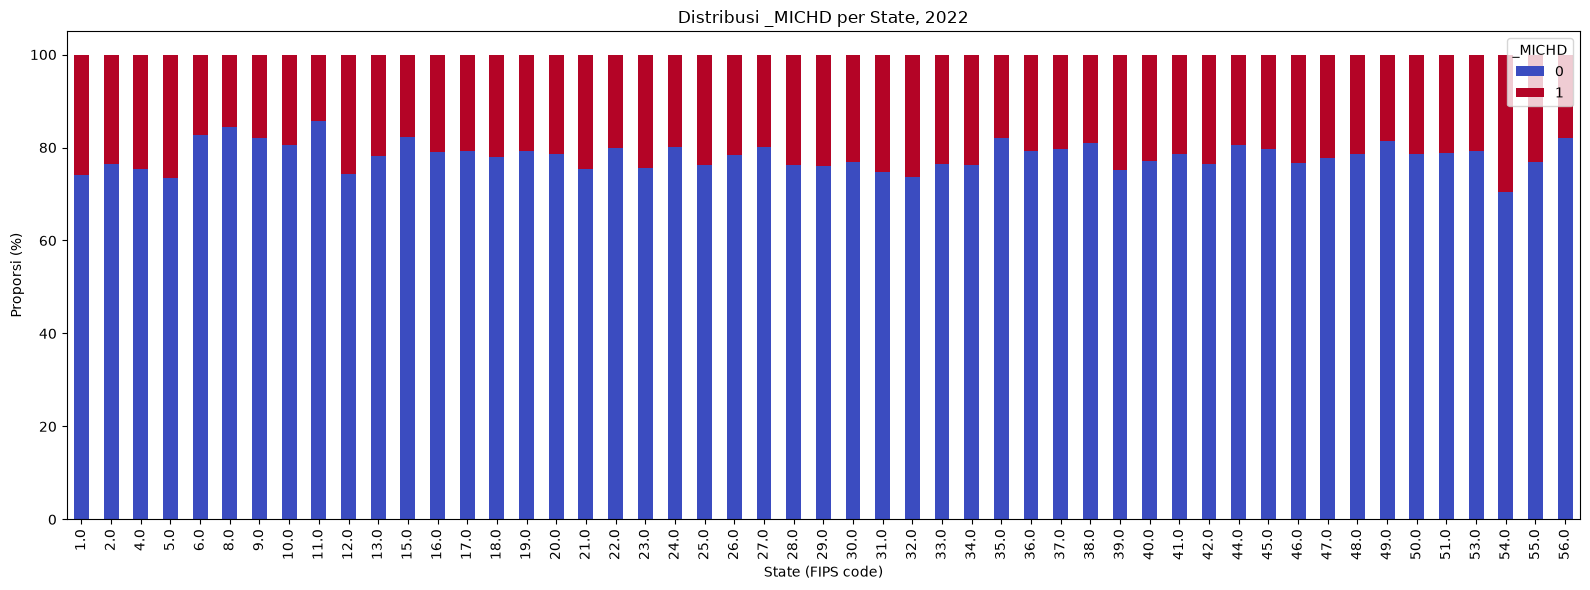

In [13]:
# %% 2022
dist2022 = cek_michd(data2022, 2022)

In [14]:
# %% cek state antar tahun
states = {
    2022: set(data2022['_STATE'].unique()),
    2023: set(data2023['_STATE'].unique()),
    2024: set(data2024['_STATE'].unique()),
    2025: set(data2025['_STATE'].unique()),
}

common = set.intersection(*states.values())
all_states = set.union(*states.values())

print("State di semua tahun:", len(common))
print("Total state unik:", len(all_states))

for yr, s in states.items():
    print(yr, "| jumlah:", len(s), "| tidak ada di tahun ini:", sorted(all_states - s))

State di semua tahun: 44
Total state unik: 51
2022 | jumlah: 51 | tidak ada di tahun ini: []
2023 | jumlah: 49 | tidak ada di tahun ini: [21.0, 42.0]
2024 | jumlah: 49 | tidak ada di tahun ini: [9.0, 47.0]
2025 | jumlah: 48 | tidak ada di tahun ini: [6.0, 28.0, 32.0]


In [15]:
# %% samakan state di semua tahun
datas = {
    2022: data2022,
    2023: data2023,
    2024: data2024,
    2025: data2025,
}

# State yang ada di semua tahun
common_states = set.intersection(*[set(df['_STATE'].unique()) for df in datas.values()])
print("Jumlah state sama:", len(common_states))
print("State yang dipakai:", sorted(common_states))

# Filter tiap tahun (tetap terpisah)
data2022 = data2022[data2022['_STATE'].isin(common_states)].reset_index(drop=True)
data2023 = data2023[data2023['_STATE'].isin(common_states)].reset_index(drop=True)
data2024 = data2024[data2024['_STATE'].isin(common_states)].reset_index(drop=True)
data2025 = data2025[data2025['_STATE'].isin(common_states)].reset_index(drop=True)

Jumlah state sama: 44
State yang dipakai: [1.0, 2.0, 4.0, 5.0, 8.0, 10.0, 11.0, 12.0, 13.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 22.0, 23.0, 24.0, 25.0, 26.0, 27.0, 29.0, 30.0, 31.0, 33.0, 34.0, 35.0, 36.0, 37.0, 38.0, 39.0, 40.0, 41.0, 44.0, 45.0, 46.0, 48.0, 49.0, 50.0, 51.0, 53.0, 54.0, 55.0, 56.0]


In [16]:
# %% verifikasi
states = {
    2022: set(data2022['_STATE'].unique()),
    2023: set(data2023['_STATE'].unique()),
    2024: set(data2024['_STATE'].unique()),
    2025: set(data2025['_STATE'].unique()),
}

print("Semua tahun sama:", all(s == states[2022] for s in states.values()))

for yr, df in {2022: data2022, 2023: data2023, 2024: data2024, 2025: data2025}.items():
    print(yr, "| baris:", len(df), "| state:", df['_STATE'].nunique())

Semua tahun sama: True
2022 | baris: 29695 | state: 44
2023 | baris: 31690 | state: 44
2024 | baris: 35598 | state: 44
2025 | baris: 28042 | state: 44


In [17]:
data2022.to_csv('brfss2022_diabetes_common.csv', index=False)
data2023.to_csv('brfss2023_diabetes_common.csv', index=False)
data2024.to_csv('brfss2024_diabetes_common.csv', index=False)
data2025.to_csv('brfss2025_diabetes_common.csv', index=False)

===== 2023 =====
Jumlah baris: 31690 | Jumlah state: 44
Encoding _MICHD: {0: 25238, 1: 6452}
_MICHD   0_n  1_n  0_pct  1_pct
_STATE                         
1.0      408  121  77.13  22.87
2.0      275   51  84.36  15.64
4.0      804  202  79.92  20.08
5.0      398  133  74.95  25.05
8.0      392   79  83.23  16.77
10.0     278   80  77.65  22.35
11.0     155   26  85.64  14.36
12.0     934  308  75.20  24.80
13.0     661  170  79.54  20.46
15.0     592  117  83.50  16.50
16.0     325   73  81.66  18.34
17.0     380   76  83.33  16.67
18.0     822  197  80.67  19.33
19.0     660  182  78.38  21.62
20.0     638  181  77.90  22.10
22.0     385  119  76.39  23.61
23.0     752  258  74.46  25.54
24.0    1233  289  81.01  18.99
25.0     417  102  80.35  19.65
26.0     638  180  78.00  22.00
27.0     872  210  80.59  19.41
29.0     452  117  79.44  20.56
30.0     442  126  77.82  22.18
31.0     994  214  82.28  17.72
33.0     400  100  80.00  20.00
34.0     518  110  82.48  17.52
35.0     26

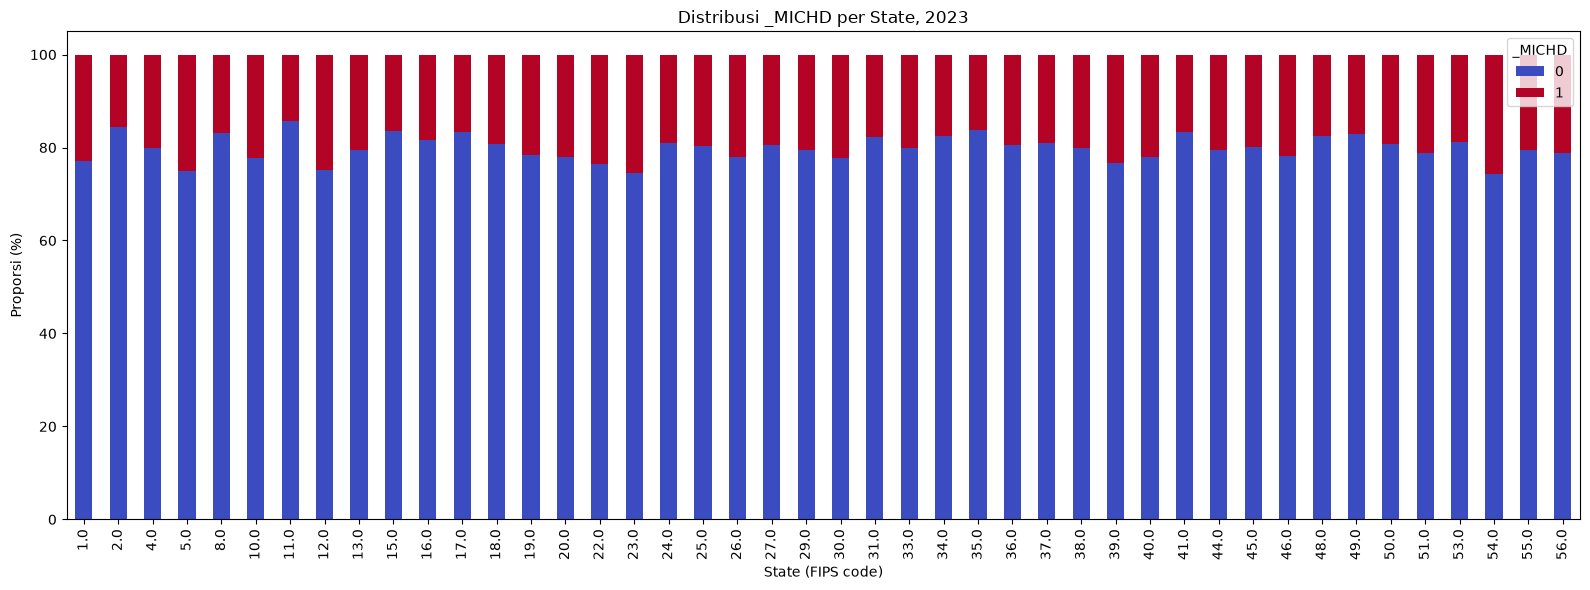

In [18]:
dist2023 = cek_michd(data2023, 2023)

State di semua tahun: 44
Total state unik: 51
2022 | jumlah: 51 | tidak ada di tahun ini: []
2023 | jumlah: 49 | tidak ada di tahun ini: [21.0, 42.0]
2024 | jumlah: 49 | tidak ada di tahun ini: [9.0, 47.0]
2025 | jumlah: 48 | tidak ada di tahun ini: [6.0, 28.0, 32.0]
State yang dipakai: [1.0, 2.0, 4.0, 5.0, 8.0, 10.0, 11.0, 12.0, 13.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 22.0, 23.0, 24.0, 25.0, 26.0, 27.0, 29.0, 30.0, 31.0, 33.0, 34.0, 35.0, 36.0, 37.0, 38.0, 39.0, 40.0, 41.0, 44.0, 45.0, 46.0, 48.0, 49.0, 50.0, 51.0, 53.0, 54.0, 55.0, 56.0]
Semua tahun sama: True
      baris_sebelum  baris_sesudah  state_sebelum  state_sesudah  \
2022          32634          29695             51             44   
2023          34253          31690             49             44   
2024          37809          35598             49             44   
2025          30245          28042             48             44   

      baris_dibuang  %_dibuang  
2022           2939       9.01  
2023           2563   

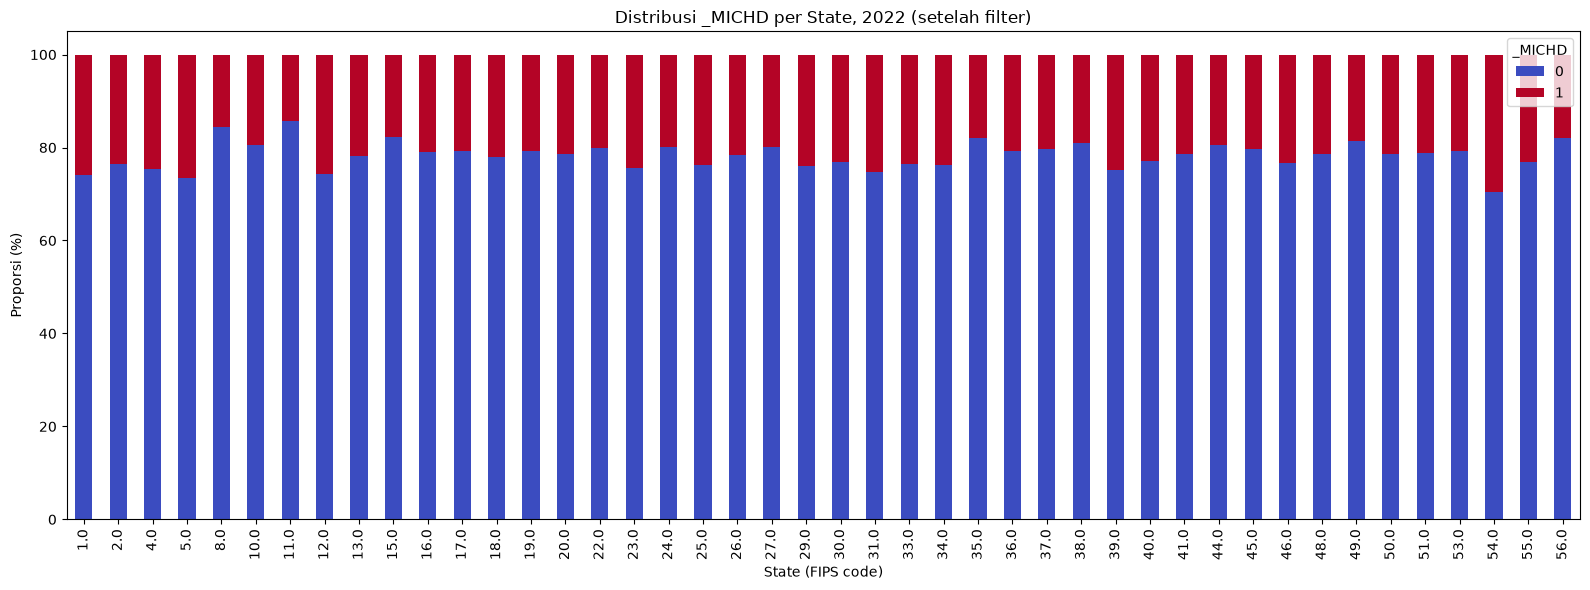

===== 2023 (setelah filter) =====
Jumlah baris: 31690 | Jumlah state: 44
Encoding _MICHD: {0: 25238, 1: 6452}
_MICHD   0_n  1_n  0_pct  1_pct
_STATE                         
1.0      408  121  77.13  22.87
2.0      275   51  84.36  15.64
4.0      804  202  79.92  20.08
5.0      398  133  74.95  25.05
8.0      392   79  83.23  16.77
10.0     278   80  77.65  22.35
11.0     155   26  85.64  14.36
12.0     934  308  75.20  24.80
13.0     661  170  79.54  20.46
15.0     592  117  83.50  16.50
16.0     325   73  81.66  18.34
17.0     380   76  83.33  16.67
18.0     822  197  80.67  19.33
19.0     660  182  78.38  21.62
20.0     638  181  77.90  22.10
22.0     385  119  76.39  23.61
23.0     752  258  74.46  25.54
24.0    1233  289  81.01  18.99
25.0     417  102  80.35  19.65
26.0     638  180  78.00  22.00
27.0     872  210  80.59  19.41
29.0     452  117  79.44  20.56
30.0     442  126  77.82  22.18
31.0     994  214  82.28  17.72
33.0     400  100  80.00  20.00
34.0     518  110  82.48  

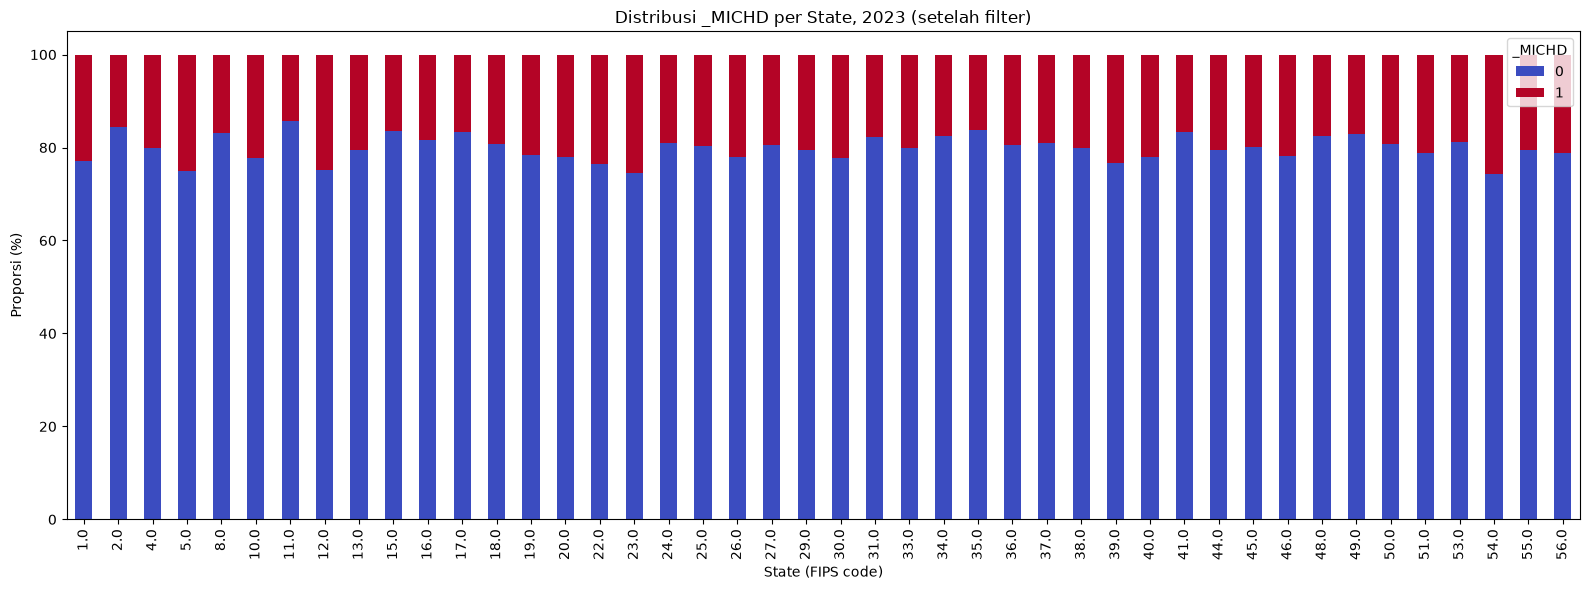

===== 2024 (setelah filter) =====
Jumlah baris: 35598 | Jumlah state: 44
Encoding _MICHD: {0: 27767, 1: 7831}
_MICHD   0_n  1_n  0_pct  1_pct
_STATE                         
1.0      458  128  78.16  21.84
2.0      293   68  81.16  18.84
4.0      587  153  79.32  20.68
5.0      422  148  74.04  25.96
8.0      516  133  79.51  20.49
10.0     318   96  76.81  23.19
11.0     167   28  85.64  14.36
12.0     957  268  78.12  21.88
13.0     530  163  76.48  23.52
15.0     461  104  81.59  18.41
16.0     219   63  77.66  22.34
17.0     989  240  80.47  19.53
18.0    1042  322  76.39  23.61
19.0     683  189  78.33  21.67
20.0     787  222  78.00  22.00
22.0     347   99  77.80  22.20
23.0     739  264  73.68  26.32
24.0    1040  256  80.25  19.75
25.0     435  101  81.16  18.84
26.0     850  263  76.37  23.63
27.0     807  235  77.45  22.55
29.0     445  135  76.72  23.28
30.0     398  114  77.73  22.27
31.0     975  287  77.26  22.74
33.0     448  130  77.51  22.49
34.0     460  113  80.28  

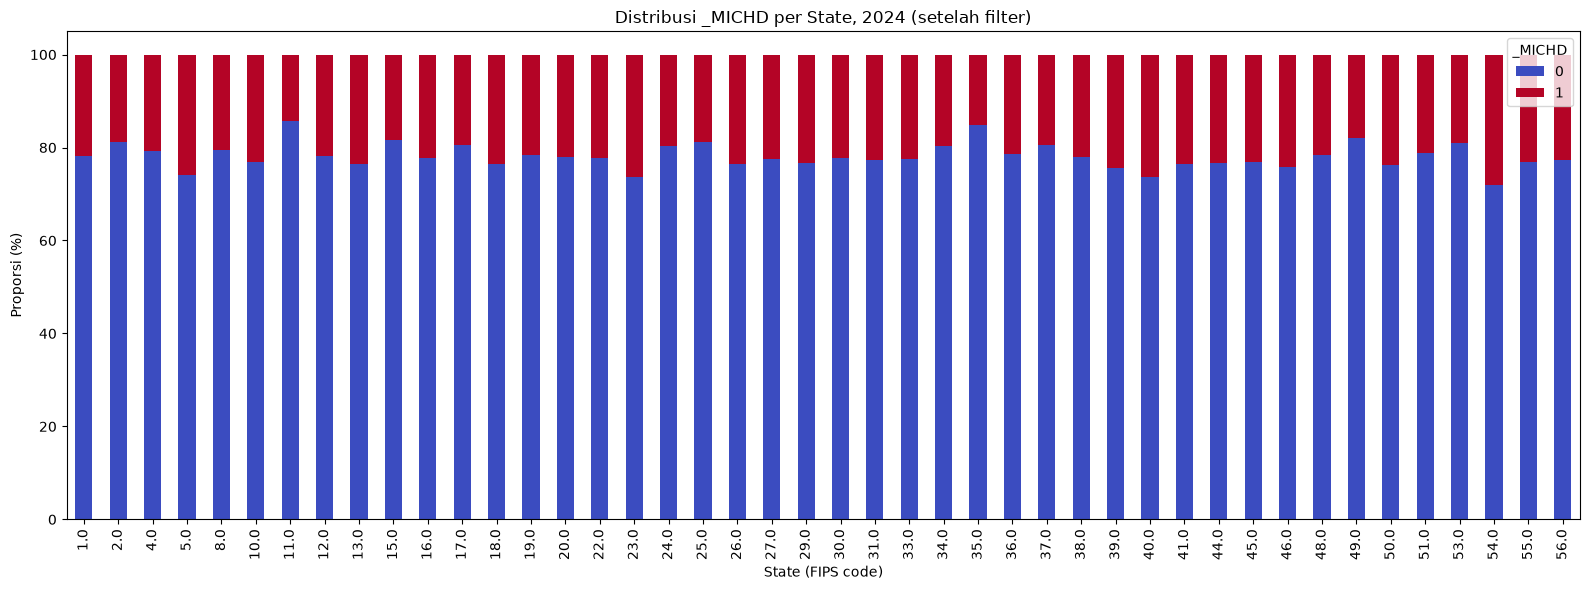

===== 2025 (setelah filter) =====
Jumlah baris: 28042 | Jumlah state: 44
Encoding _MICHD: {0: 22186, 1: 5856}
_MICHD   0_n  1_n  0_pct  1_pct
_STATE                         
1.0      396  113  77.80  22.20
2.0      303   83  78.50  21.50
4.0      422  109  79.47  20.53
5.0      394  147  72.83  27.17
8.0      498   99  83.42  16.58
10.0     303   87  77.69  22.31
11.0     175   25  87.50  12.50
12.0     974  297  76.63  23.37
13.0     460  146  75.91  24.09
15.0     491  111  81.56  18.44
16.0     158   47  77.07  22.93
17.0     931  255  78.50  21.50
18.0     532  126  80.85  19.15
19.0     619  190  76.51  23.49
20.0     707  173  80.34  19.66
22.0     431  117  78.65  21.35
23.0     745  251  74.80  25.20
24.0     963  195  83.16  16.84
25.0     486  104  82.37  17.63
26.0     775  201  79.41  20.59
27.0     920  233  79.79  20.21
29.0     342  117  74.51  25.49
30.0     334   91  78.59  21.41
31.0     581  151  79.37  20.63
33.0     400  120  76.92  23.08
34.0     407   94  81.24  

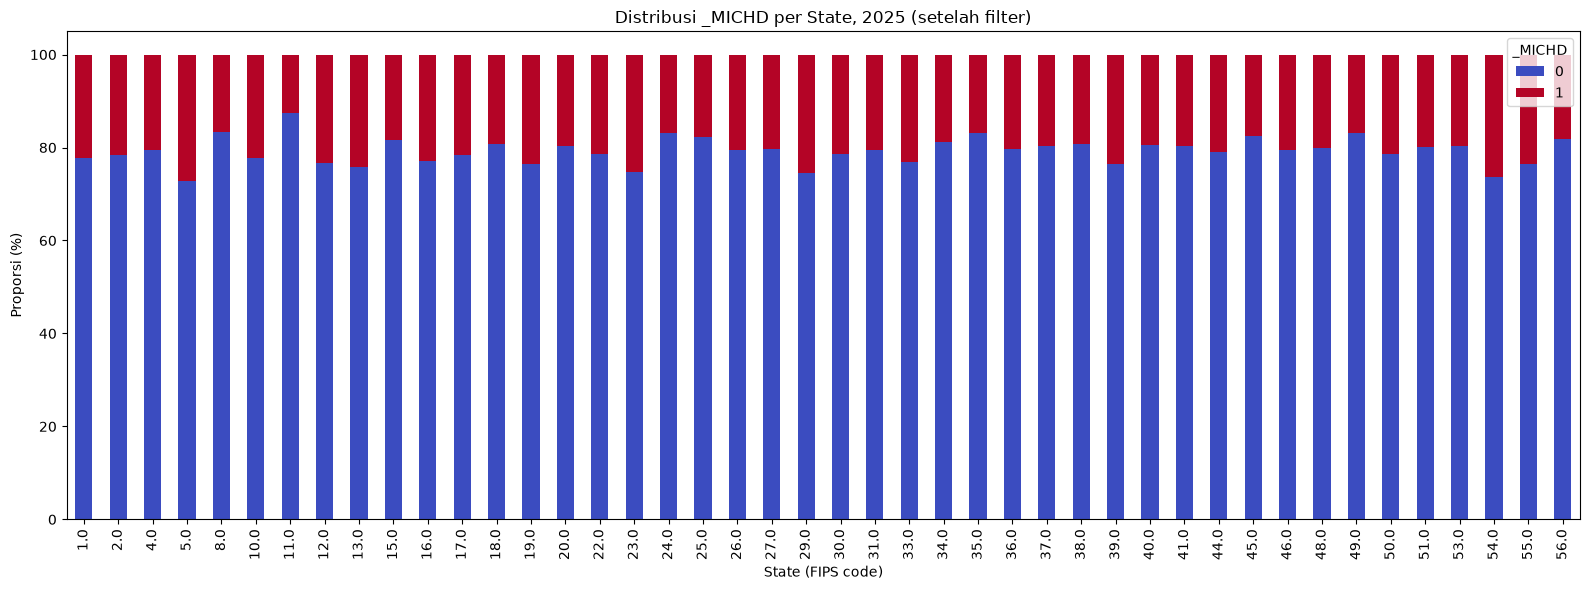

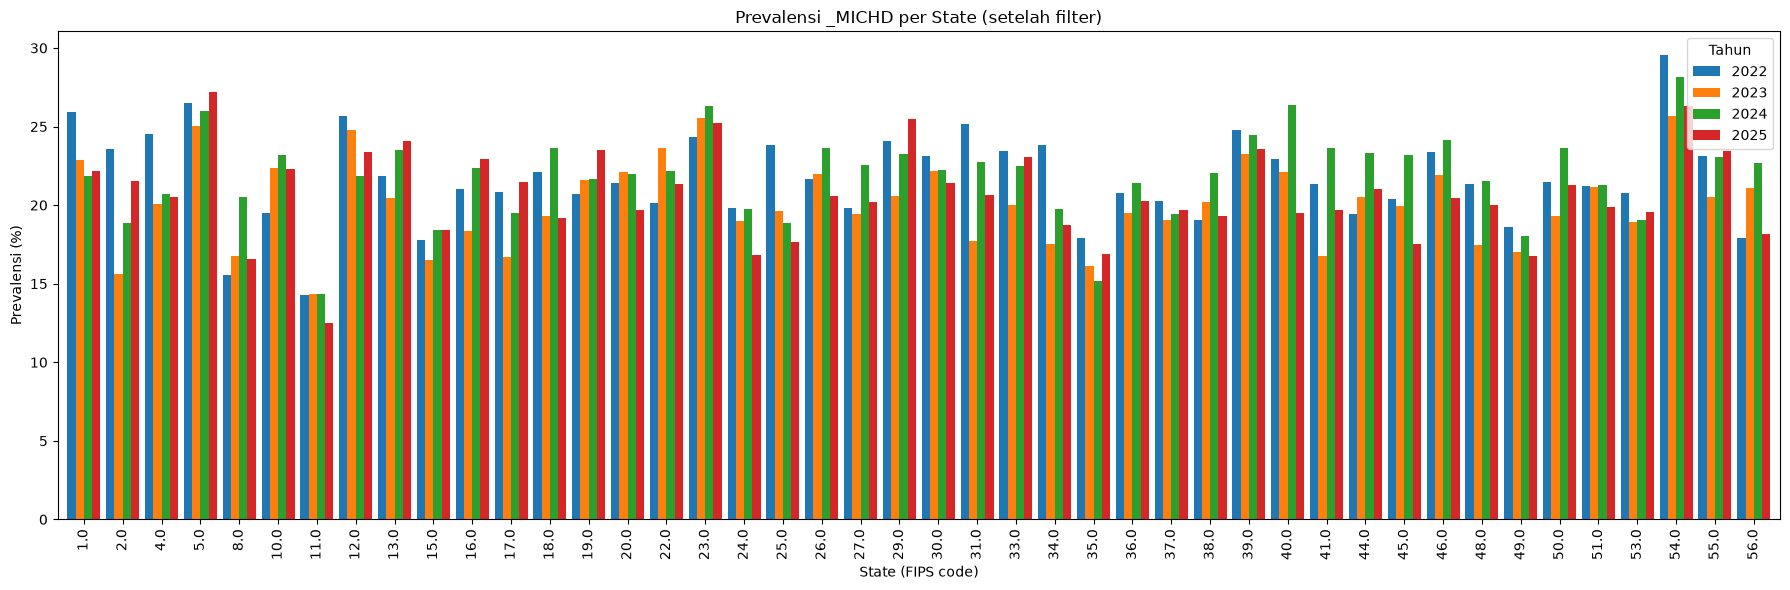

         2022   2023   2024   2025
_STATE                            
1.0     25.90  22.87  21.84  22.20
2.0     23.58  15.64  18.84  21.50
4.0     24.52  20.08  20.68  20.53
5.0     26.53  25.05  25.96  27.17
8.0     15.55  16.77  20.49  16.58
10.0    19.51  22.35  23.19  22.31
11.0    14.29  14.36  14.36  12.50
12.0    25.69  24.80  21.88  23.37
13.0    21.84  20.46  23.52  24.09
15.0    17.81  16.50  18.41  18.44
16.0    21.01  18.34  22.34  22.93
17.0    20.85  16.67  19.53  21.50
18.0    22.13  19.33  23.61  19.15
19.0    20.72  21.62  21.67  23.49
20.0    21.41  22.10  22.00  19.66
22.0    20.16  23.61  22.20  21.35
23.0    24.30  25.54  26.32  25.20
24.0    19.82  18.99  19.75  16.84
25.0    23.82  19.65  18.84  17.63
26.0    21.64  22.00  23.63  20.59
27.0    19.80  19.41  22.55  20.21
29.0    24.06  20.56  23.28  25.49
30.0    23.11  22.18  22.27  21.41
31.0    25.17  17.72  22.74  20.63
33.0    23.46  20.00  22.49  23.08
34.0    23.80  17.52  19.72  18.76
35.0    17.88  16.14

In [19]:
# %% 1. Import & baca data
import pandas as pd
import matplotlib.pyplot as plt

tahun_list = [2022, 2023, 2024, 2025]
data = {yr: pd.read_csv(f'brfss{yr}_diabetes.csv') for yr in tahun_list}

# Simpan jumlah baris & state sebelum filter
n_before = {yr: len(df) for yr, df in data.items()}
s_before = {yr: df['_STATE'].nunique() for yr, df in data.items()}

# %% 2. Fungsi cek distribusi _MICHD per state
def cek_michd(df, judul, tampil_tabel=True):
    print(f"===== {judul} =====")
    print("Jumlah baris:", len(df), "| Jumlah state:", df['_STATE'].nunique())
    print("Encoding _MICHD:", df['_MICHD'].value_counts().to_dict())

    counts = pd.crosstab(df['_STATE'], df['_MICHD'])
    props = pd.crosstab(df['_STATE'], df['_MICHD'], normalize='index') * 100
    dist = counts.join(props, lsuffix='_n', rsuffix='_pct').round(2)
    if tampil_tabel:
        print(dist)

    props.plot(kind='bar', stacked=True, figsize=(16, 6), colormap='coolwarm')
    plt.title(f'Distribusi _MICHD per State, {judul}')
    plt.xlabel('State (FIPS code)')
    plt.ylabel('Proporsi (%)')
    plt.legend(title='_MICHD')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
    return dist

# %% 3. Cek state antar tahun (sebelum filter)
states = {yr: set(df['_STATE'].unique()) for yr, df in data.items()}
common_states = set.intersection(*states.values())
all_states = set.union(*states.values())

print("State di semua tahun:", len(common_states))
print("Total state unik:", len(all_states))
for yr, s in states.items():
    print(yr, "| jumlah:", len(s), "| tidak ada di tahun ini:", sorted(all_states - s))

# %% 4. Filter: samakan state di semua tahun
data_f = {
    yr: df[df['_STATE'].isin(common_states)].reset_index(drop=True)
    for yr, df in data.items()
}

# Alias supaya tetap bisa dipanggil seperti sebelumnya
data2022, data2023, data2024, data2025 = (data_f[yr] for yr in tahun_list)

print("State yang dipakai:", sorted(common_states))

# %% 5. Verifikasi state sudah sama
states_f = {yr: set(df['_STATE'].unique()) for yr, df in data_f.items()}
print("Semua tahun sama:", all(s == states_f[2022] for s in states_f.values()))

# %% 6. Ringkasan sebelum vs sesudah filter
ringkasan = pd.DataFrame({
    'baris_sebelum': n_before,
    'baris_sesudah': {yr: len(df) for yr, df in data_f.items()},
    'state_sebelum': s_before,
    'state_sesudah': {yr: df['_STATE'].nunique() for yr, df in data_f.items()},
})
ringkasan['baris_dibuang'] = ringkasan['baris_sebelum'] - ringkasan['baris_sesudah']
ringkasan['%_dibuang'] = (ringkasan['baris_dibuang'] / ringkasan['baris_sebelum'] * 100).round(2)
print(ringkasan)

# %% 7. Simpan hasil filter
for yr, df in data_f.items():
    df.to_csv(f'brfss{yr}_diabetes_common.csv', index=False)

# %% 8. Distribusi total _MICHD per tahun (tanpa per state)
for yr, df in data_f.items():
    vc = df['_MICHD'].value_counts(normalize=True).mul(100).round(2)
    print(yr, vc.to_dict())

# %% 9a. Distribusi per state, 2022 (setelah filter)
dist2022 = cek_michd(data2022, '2022 (setelah filter)')

# %% 9b. 2023
dist2023 = cek_michd(data2023, '2023 (setelah filter)')

# %% 9c. 2024
dist2024 = cek_michd(data2024, '2024 (setelah filter)')

# %% 9d. 2025
dist2025 = cek_michd(data2025, '2025 (setelah filter)')

# %% 10. Perbandingan prevalensi per state, 4 tahun berdampingan
POS = 1  # kode kelas positif (ada MI/CHD); sesuaikan dengan output "Encoding _MICHD"

prev = pd.DataFrame({
    yr: df.groupby('_STATE')['_MICHD'].apply(lambda s: (s == POS).mean() * 100)
    for yr, df in data_f.items()
})

prev.plot(kind='bar', figsize=(18, 6), width=0.85)
plt.title('Prevalensi _MICHD per State (setelah filter)')
plt.xlabel('State (FIPS code)')
plt.ylabel('Prevalensi (%)')
plt.legend(title='Tahun')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print(prev.round(2))